# Per-update predictors for RankMe and variance

**Complete** · Finished all four predictors · Completion ETA 0 min

432/432 jobs saved. Paired scores through 80,000 arrivals. Updated 2026-11-11T14:26:36+01:00.

## Paired RMSE over the stream

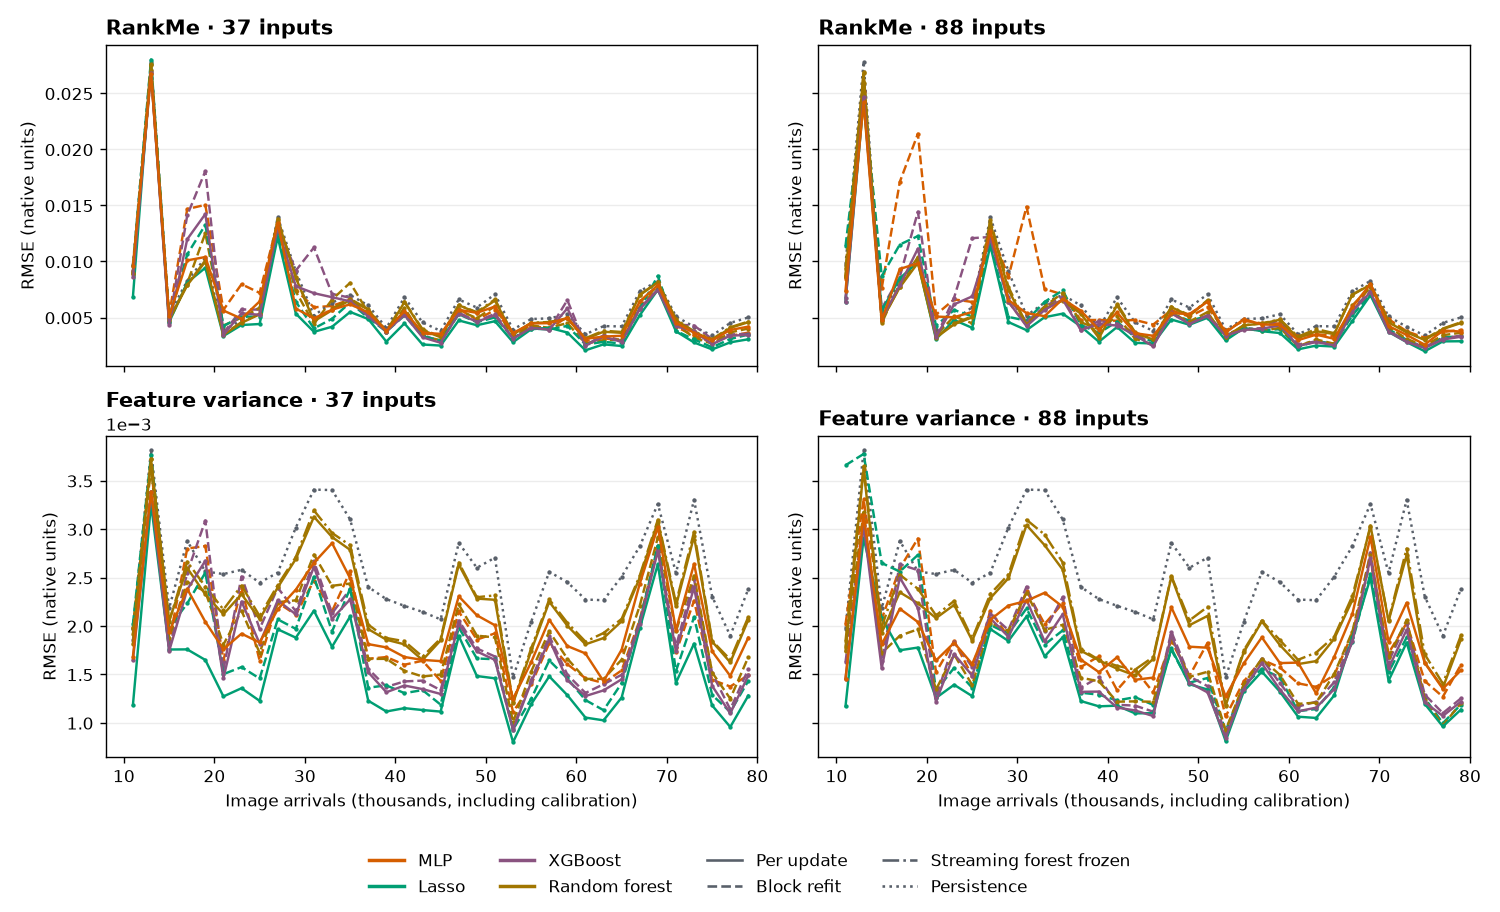

## Pooled scores and gains over persistence

| Predictor | Inputs | Learning | RankMe RMSE | Variance RMSE | RankMe gain | Variance gain |
| --- | --- | --- | --- | --- | --- | --- |
| Persistence | — | — | 0.00786233 | 0.00261077 | — | — |
| Lasso | 88 inputs | per update | 0.00635691 | 0.00157143 | +19.1% | +39.8% |
| Lasso | 88 inputs | refit | 0.00721923 | 0.0018589 | +8.2% | +28.8% |
| Lasso | 37 inputs | per update | 0.00676244 | 0.00160266 | +14.0% | +38.6% |
| Lasso | 37 inputs | refit | 0.00744366 | 0.0018401 | +5.3% | +29.5% |
| MLP | 88 inputs | per update | 0.00697043 | 0.00190059 | +11.3% | +27.2% |
| MLP | 88 inputs | refit | 0.00874316 | 0.00188292 | -11.2% | +27.9% |
| MLP | 37 inputs | per update | 0.00744088 | 0.00208865 | +5.4% | +20.0% |
| MLP | 37 inputs | refit | 0.00795298 | 0.00200869 | -1.2% | +23.1% |
| Random forest | 88 inputs | per update | 0.00728838 | 0.00214394 | +7.3% | +17.9% |
| Random forest | 88 inputs | refit | 0.00695484 | 0.00172017 | +11.5% | +34.1% |
| Random forest | 37 inputs | per update | 0.00751352 | 0.00229815 | +4.4% | +12.0% |
| Random forest | 37 inputs | refit | 0.00745397 | 0.00202805 | +5.2% | +22.3% |
| Streaming forest frozen | 88 inputs | frozen | 0.00738359 | 0.00219317 | +6.1% | +16.0% |
| Streaming forest frozen | 37 inputs | frozen | 0.00756479 | 0.00233252 | +3.8% | +10.7% |
| XGBoost | 88 inputs | per update | 0.00674595 | 0.00168576 | +14.2% | +35.4% |
| XGBoost | 88 inputs | refit | 0.0073241 | 0.00177346 | +6.8% | +32.1% |
| XGBoost | 37 inputs | per update | 0.00757673 | 0.00189397 | +3.6% | +27.5% |
| XGBoost | 37 inputs | refit | 0.00821337 | 0.00197781 | -4.5% | +24.2% |

## Protocol

The worker starts once notebook 170 is complete. It reuses its seeds, logged actions, 37- and 88-input matrices, slow-bank health targets, and paired 2,000-arrival scoring windows. Both action models start each block using the same past-data window as the refit baseline. Each successful update is forecast before its outcome enters the learner.

- MLP takes one Adam step per observed outcome from the shared block fit.
- Lasso starts from the shared batch solution and takes a proximal L1 step after each outcome.
- XGBoost keeps its fitted splits and applies a decaying residual correction to the visited leaves.
- Streaming Random Forest uses eight River adaptive trees per action and health metric. Its own frozen shadow shares its initialization. Notebook 170 supplies the batch forest reference.

In [ ]:
# Run this cell to refresh the queued or running job in this notebook.
from IPython.display import clear_output, display, Image, Markdown
from pathlib import Path
import json, time

folder = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\per-update-predictors')
while True:
    try:
        status = json.loads((folder / 'status.json').read_text(encoding='utf-8'))
    except (FileNotFoundError, PermissionError, ValueError):
        time.sleep(2)
        continue
    key = 'queue_seconds' if status['state'] == 'queued' else 'eta_seconds'
    remaining = status[key]
    estimate = f'{remaining / 60:.1f} min' if remaining is not None else 'estimating'
    label = 'until start' if key == 'queue_seconds' else 'until completion'
    clear_output(wait=True)
    display(Markdown(f"**{status['state']}** · {status['stage']} · {estimate} {label} · "
                     f"{status['completed_jobs']}/{status['total_jobs']} jobs"))
    if status['error']:
        display(Markdown(status['error']))
    try:
        display(Image(data=(folder / 'rmse.png').read_bytes()))
    except (FileNotFoundError, PermissionError):
        pass
    if status['state'] in ('complete', 'failed', 'stopped'):
        break
    time.sleep(10)
